# MLOps Assignment-1

In [ ]:
! pwd
! which python3

/home/coder/BITS-MLOps-AIMLZG523_Assignment-1
/home/coder/BITS-MLOps-AIMLZG523_Assignment-1/.venv/bin/python


In [2]:
# ==============================================================================
# Cell 1: Environment Setup & Imports
# ==============================================================================
%matplotlib inline

import os
import json
import logging
import tempfile
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
import requests

import mlflow
import mlflow.sklearn
from mlflow.models import infer_signature

from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, roc_auc_score,
    roc_curve, classification_report, ConfusionMatrixDisplay
)

# Plotting style configuration
sns.set_theme(style="whitegrid", context="notebook")
PALETTE = {"No disease": "#4C78A8", "Disease": "#E45756"}
LABELS = {0: "No disease", 1: "Disease"}

# Global Constants
RANDOM_STATE = 42
TEST_SIZE = 0.2
CV_FOLDS = 5

COLUMNS = [
    "age", "sex", "cp", "trestbps", "chol", "fbs", "restecg",
    "thalach", "exang", "oldpeak", "slope", "ca", "thal", "target"
]
NUMERIC_FEATURES = ["age", "trestbps", "chol", "thalach", "oldpeak"]
CATEGORICAL_FEATURES = ["sex", "cp", "fbs", "restecg", "exang", "slope", "ca", "thal"]
FEATURES = NUMERIC_FEATURES + CATEGORICAL_FEATURES
TARGET = "target"

In [3]:
# ==============================================================================
# Cell 2: Data Acquisition & Cleaning
# ==============================================================================
DATA_URL = "https://archive.ics.uci.edu/ml/machine-learning-databases/heart-disease/processed.cleveland.data"
DATA_DIR = Path("data")
DATA_DIR.mkdir(exist_ok=True)
RAW_PATH = DATA_DIR / "heart_disease.csv"
CLEAN_PATH = DATA_DIR / "heart_disease_clean.csv"

# Fetch raw dataset if not present locally
if not RAW_PATH.exists():
    resp = requests.get(DATA_URL)
    RAW_PATH.write_text(resp.text)

# Load raw dataset treating '?' as missing
df_raw = pd.read_csv(RAW_PATH, names=COLUMNS, na_values="?")

# Clean dataset
df_clean = df_raw.copy()
for col in COLUMNS:
    df_clean[col] = pd.to_numeric(df_clean[col], errors="coerce")

df_clean = df_clean.drop_duplicates().reset_index(drop=True)
# Convert target to binary: 0 = No Disease, 1..4 = Disease Present
df_clean[TARGET] = (df_clean[TARGET] > 0).astype(int)
df_clean.to_csv(CLEAN_PATH, index=False)

print(f"Raw shape: {df_raw.shape} | Clean shape: {df_clean.shape}")
print("Target balance:\n", df_clean[TARGET].value_counts(normalize=True).round(3))

Raw shape: (304, 14) | Clean shape: (304, 14)
Target balance:
 target
0    0.543
1    0.457
Name: proportion, dtype: float64


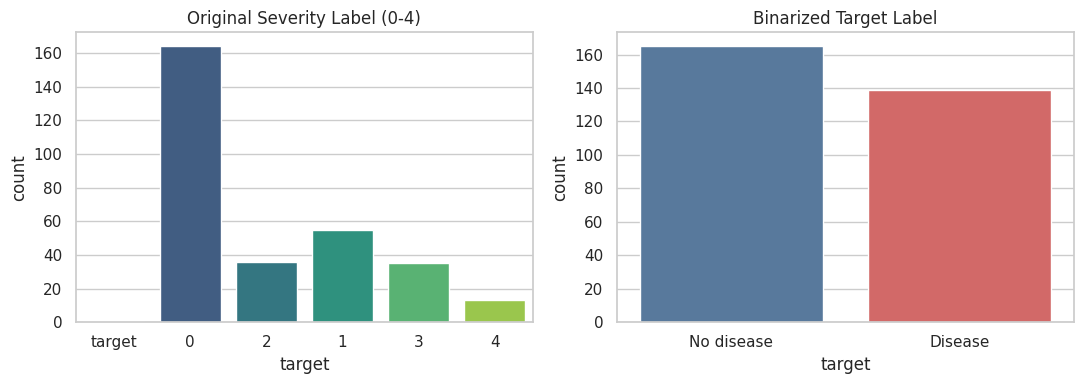

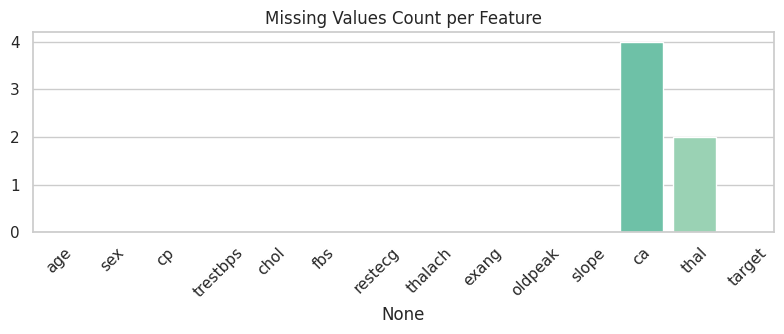

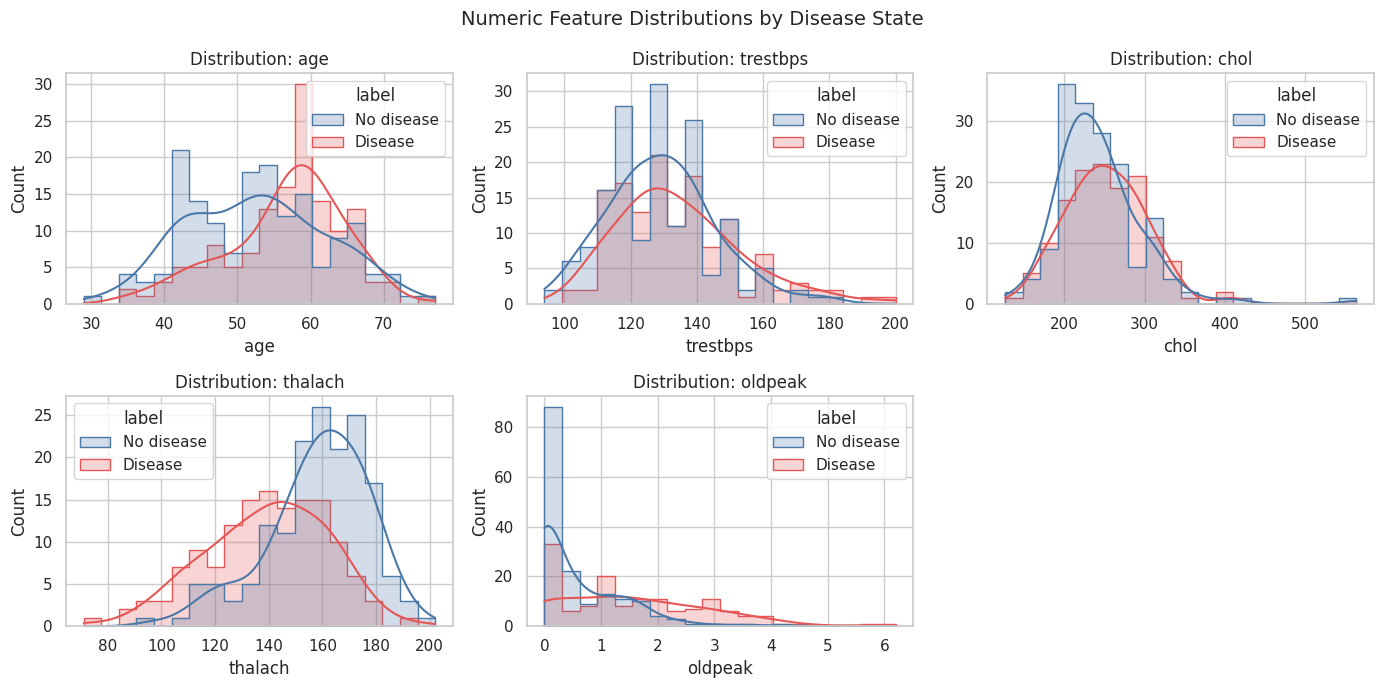

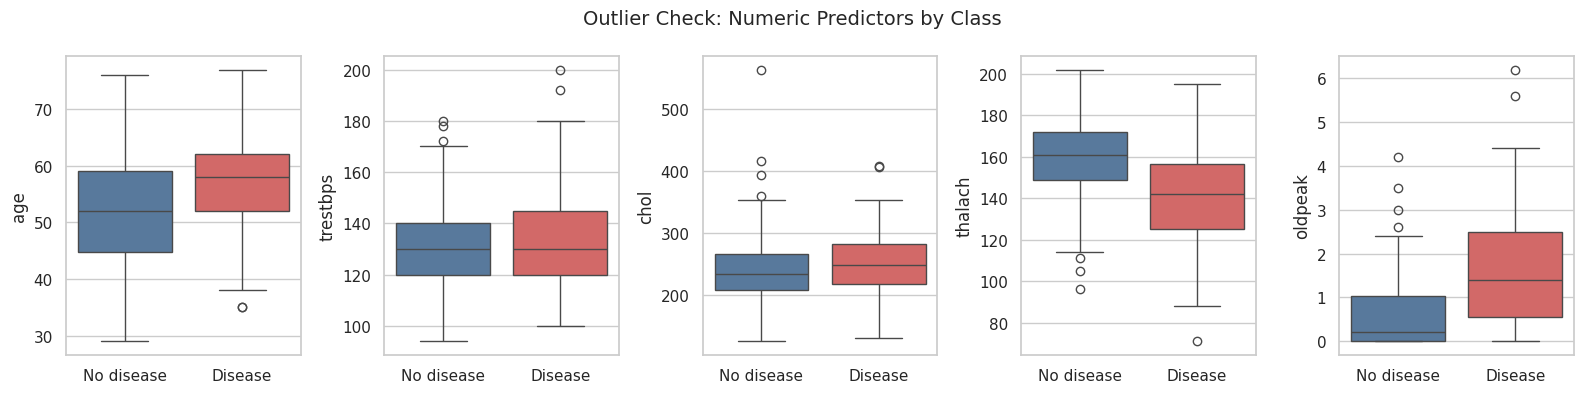

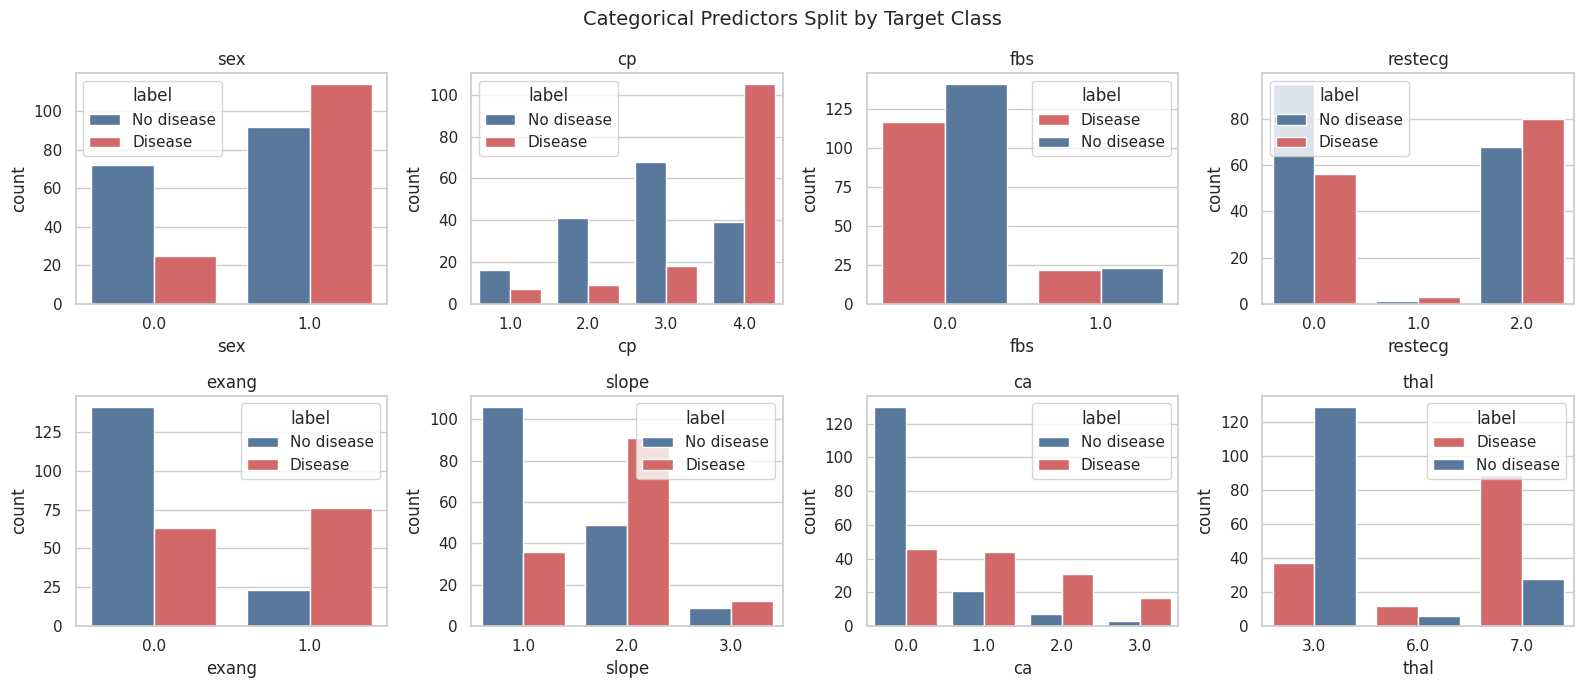

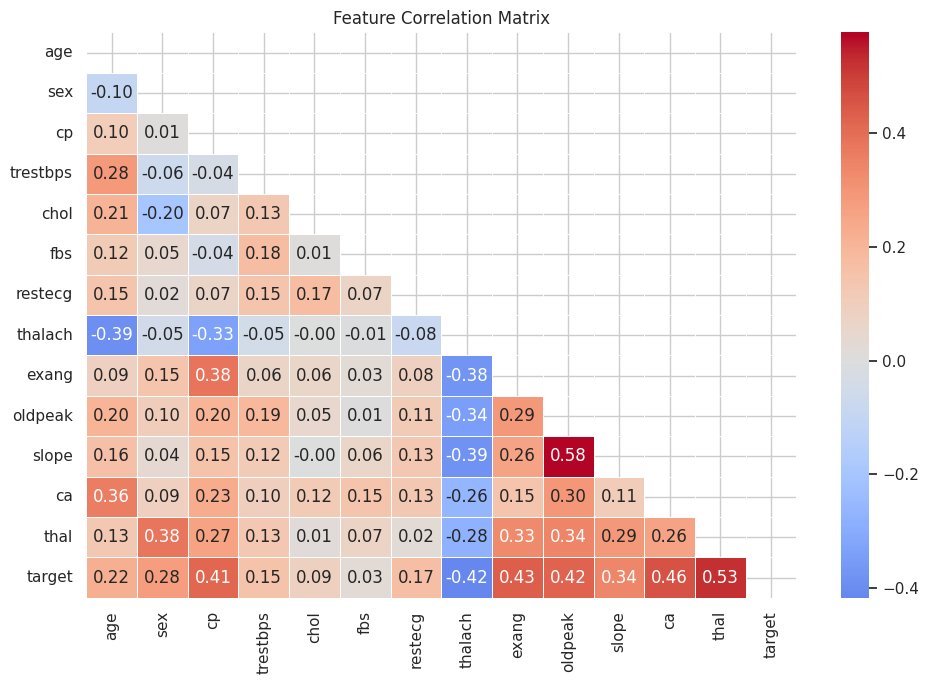

In [4]:
# ==============================================================================
# Cell 3: Exploratory Data Analysis (EDA) Visualizations
# ==============================================================================
# 1. Target Class Balance (Severity vs Binary)
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
sns.countplot(x=df_raw[TARGET], hue=df_raw[TARGET], palette="viridis", legend=False, ax=axes[0])
axes[0].set_title("Original Severity Label (0-4)")

labelled_target = df_clean[TARGET].map(LABELS)
sns.countplot(x=labelled_target, hue=labelled_target, palette=PALETTE, order=list(LABELS.values()), legend=False, ax=axes[1])
axes[1].set_title("Binarized Target Label")
plt.tight_layout()
plt.show()

# 2. Missing Values Bar Plot
miss = df_raw.isna().sum()
fig, ax = plt.subplots(figsize=(8, 3.5))
sns.barplot(x=miss.index, y=miss.values, hue=miss.index, palette="mako", legend=False, ax=ax)
ax.set_title("Missing Values Count per Feature")
ax.tick_params(axis="x", rotation=45)
plt.tight_layout()
plt.show()

# 3. Numeric Feature Histograms with KDE
fig, axes = plt.subplots(2, 3, figsize=(14, 7))
data_mapped = df_clean.assign(label=df_clean[TARGET].map(LABELS))
for ax, col in zip(axes.ravel(), NUMERIC_FEATURES):
    sns.histplot(data=data_mapped, x=col, hue="label", palette=PALETTE, bins=20, kde=True, element="step", ax=ax)
    ax.set_title(f"Distribution: {col}")
axes.ravel()[-1].axis("off")
fig.suptitle("Numeric Feature Distributions by Disease State", fontsize=14)
plt.tight_layout()
plt.show()

# 4. Outlier Analysis via Boxplots
fig, axes = plt.subplots(1, len(NUMERIC_FEATURES), figsize=(16, 4))
for ax, col in zip(axes, NUMERIC_FEATURES):
    sns.boxplot(data=data_mapped, x="label", y=col, hue="label", palette=PALETTE, legend=False, ax=ax)
    ax.set_xlabel("")
fig.suptitle("Outlier Check: Numeric Predictors by Class", fontsize=14)
plt.tight_layout()
plt.show()

# 5. Categorical Features Distribution
fig, axes = plt.subplots(2, 4, figsize=(16, 7))
for ax, col in zip(axes.ravel(), CATEGORICAL_FEATURES):
    sns.countplot(data=data_mapped, x=col, hue="label", palette=PALETTE, ax=ax)
    ax.set_title(col)
fig.suptitle("Categorical Predictors Split by Target Class", fontsize=14)
plt.tight_layout()
plt.show()

# 6. Feature Correlation Heatmap
corr = df_clean.corr(numeric_only=True)
mask = np.triu(np.ones_like(corr, dtype=bool))
fig, ax = plt.subplots(figsize=(10, 7))
sns.heatmap(corr, mask=mask, annot=True, fmt=".2f", cmap="coolwarm", center=0, linewidths=0.5, ax=ax)
ax.set_title("Feature Correlation Matrix")
plt.tight_layout()
plt.show()

In [5]:
# ==============================================================================
# Cell 4: Preprocessing Pipeline Construction & Dataset Splitting
# ==============================================================================
def build_preprocessor():
    numeric_pipe = Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
    ])
    categorical_pipe = Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("encoder", OneHotEncoder(handle_unknown="ignore", sparse_output=False)),
    ])
    return ColumnTransformer([
        ("num", numeric_pipe, NUMERIC_FEATURES),
        ("cat", categorical_pipe, CATEGORICAL_FEATURES),
    ])

# Separate features and target label
X = df_clean[FEATURES]
y = df_clean[TARGET]

# Stratified split to preserve target class balance
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=TEST_SIZE, random_state=RANDOM_STATE, stratify=y
)

cv = StratifiedKFold(n_splits=CV_FOLDS, shuffle=True, random_state=RANDOM_STATE)
print(f"Train set: {X_train.shape[0]} rows | Test set: {X_test.shape[0]} rows")

Train set: 243 rows | Test set: 61 rows


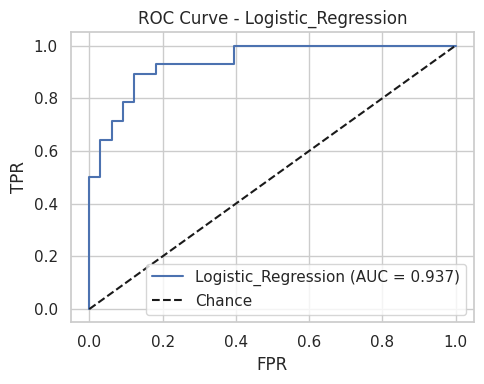

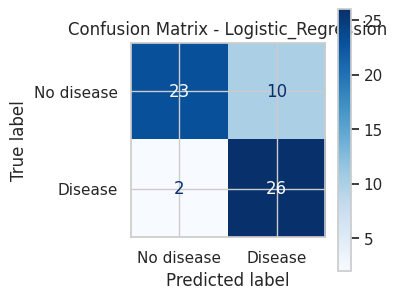

[Logistic_Regression] Best CV ROC-AUC: 0.9056 | Test ROC-AUC: 0.9372


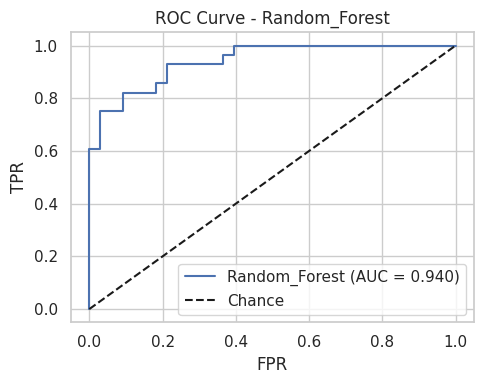

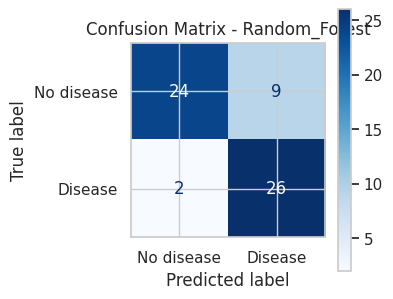

[Random_Forest] Best CV ROC-AUC: 0.8987 | Test ROC-AUC: 0.9405


In [6]:
# ==============================================================================
# Cell 5: Hyperparameter Tuning, Evaluation & MLflow Experiment Tracking
# ==============================================================================
# MLflow local tracking setup
mlflow.set_tracking_uri("file:./mlruns")
mlflow.set_experiment("Heart_Disease_Classification")

candidate_grids = {
    "Logistic_Regression": (
        LogisticRegression(max_iter=2000, random_state=RANDOM_STATE),
        {"classifier__C": [0.01, 0.1, 1.0, 10.0]}
    ),
    "Random_Forest": (
        RandomForestClassifier(random_state=RANDOM_STATE),
        {
            "classifier__n_estimators": [100, 200],
            "classifier__max_depth": [3, 5, 8],
            "classifier__min_samples_leaf": [1, 3],
        }
    )
}

scoring = ["accuracy", "precision", "recall", "roc_auc"]
results = {}

for name, (estimator, grid) in candidate_grids.items():
    pipe = Pipeline([("preprocessor", build_preprocessor()), ("classifier", estimator)])
    search = GridSearchCV(pipe, grid, scoring=scoring, refit="roc_auc", cv=cv)
    
    with mlflow.start_run(run_name=name) as run:
        search.fit(X_train, y_train)
        best_model = search.best_estimator_
        
        # Performance evaluation on holdout test set
        y_pred = best_model.predict(X_test)
        y_proba = best_model.predict_proba(X_test)[:, 1]
        
        test_auc = roc_auc_score(y_test, y_proba)
        test_acc = accuracy_score(y_test, y_pred)
        best_cv_auc = search.best_score_
        
        # Log Hyperparameters & Evaluation Metrics
        best_params = {k.replace("classifier__", ""): v for k, v in search.best_params_.items()}
        mlflow.log_params(best_params)
        mlflow.log_metrics({
            "cv_roc_auc": best_cv_auc,
            "test_roc_auc": test_auc,
            "test_accuracy": test_acc,
            "test_precision": precision_score(y_test, y_pred),
            "test_recall": recall_score(y_test, y_pred)
        })
        
        # 1. ROC Curve Plot
        fpr, tpr, _ = roc_curve(y_test, y_proba)
        fig, ax = plt.subplots(figsize=(5, 4))
        ax.plot(fpr, tpr, label=f"{name} (AUC = {test_auc:.3f})")
        ax.plot([0, 1], [0, 1], "k--", label="Chance")
        ax.set(xlabel="FPR", ylabel="TPR", title=f"ROC Curve - {name}")
        ax.legend(loc="lower right")
        plt.tight_layout()
        plt.show()
        
        # 2. Confusion Matrix Plot
        fig, ax = plt.subplots(figsize=(4, 3.5))
        ConfusionMatrixDisplay.from_predictions(
            y_test, y_pred, display_labels=["No disease", "Disease"], cmap="Blues", ax=ax
        )
        ax.set_title(f"Confusion Matrix - {name}")
        plt.tight_layout()
        plt.show()
        
        # Log model signature and artifacts to MLflow
        mlflow.sklearn.log_model(
            best_model, "model",
            signature=infer_signature(X_test, best_model.predict_proba(X_test))
        )
        
        results[name] = {
            "pipeline": best_model,
            "run_id": run.info.run_id,
            "cv_roc_auc": best_cv_auc,
            "test_roc_auc": test_auc,
            "test_accuracy": test_acc,
            "best_params": best_params
        }
        print(f"[{name}] Best CV ROC-AUC: {best_cv_auc:.4f} | Test ROC-AUC: {test_auc:.4f}")

In [7]:
# ==============================================================================
# Cell 6: Champion Selection & Model Serialization
# ==============================================================================
# Select champion model based on cross-validated ROC-AUC
champion_name = max(results, key=lambda n: results[n]["cv_roc_auc"])
champion = results[champion_name]

MODELS_DIR = Path("models")
MODELS_DIR.mkdir(exist_ok=True)
MODEL_PATH = MODELS_DIR / "best_model.pkl"
META_PATH = MODELS_DIR / "model_metadata.json"

# Save champion pipeline binary
joblib.dump(champion["pipeline"], MODEL_PATH)

# Save accompanying metadata JSON
metadata = {
    "model_name": champion_name,
    "mlflow_run_id": champion["run_id"],
    "best_params": champion["best_params"],
    "metrics": {
        "cv_roc_auc": round(champion["cv_roc_auc"], 4),
        "test_roc_auc": round(champion["test_roc_auc"], 4),
        "test_accuracy": round(champion["test_accuracy"], 4),
    },
    "features": FEATURES
}
META_PATH.write_text(json.dumps(metadata, indent=2))

print(f"Selected Champion Model: {champion_name}")
print(f"Model saved to: {MODEL_PATH.resolve()}")
print(json.dumps(metadata, indent=2))


# Load persisted champion model for scoring verification
loaded_model = joblib.load(MODEL_PATH)

sample_patient = {
    "age": 63.0, "sex": 1.0, "cp": 1.0, "trestbps": 145.0, "chol": 233.0,
    "fbs": 1.0, "restecg": 2.0, "thalach": 150.0, "exang": 0.0,
    "oldpeak": 2.3, "slope": 3.0, "ca": 0.0, "thal": 6.0
}

input_df = pd.DataFrame([sample_patient], columns=FEATURES)
probability = float(loaded_model.predict_proba(input_df)[0][1])
prediction = int(probability >= 0.5)

print("\n--- Model Inference Results ---")
print(f"Patient Assessment : {'High Risk (Disease)' if prediction == 1 else 'Low Risk (Normal)'}")
print(f"Disease Probability : {probability:.4f}")
print(f"Confidence Score    : {probability if prediction == 1 else 1 - probability:.4f}")


Selected Champion Model: Logistic_Regression
Model saved to: /home/coder/BITS-MLOps-AIMLZG523_Assignment-1/models/best_model.pkl
{
  "model_name": "Logistic_Regression",
  "mlflow_run_id": "36a83bb216664e84913b06352f4f3a21",
  "best_params": {
    "C": 0.1
  },
  "metrics": {
    "cv_roc_auc": 0.9056,
    "test_roc_auc": 0.9372,
    "test_accuracy": 0.8033
  },
  "features": [
    "age",
    "trestbps",
    "chol",
    "thalach",
    "oldpeak",
    "sex",
    "cp",
    "fbs",
    "restecg",
    "exang",
    "slope",
    "ca",
    "thal"
  ]
}

--- Model Inference Results ---
Patient Assessment : High Risk (Disease)
Disease Probability : 0.5504
Confidence Score    : 0.5504
